In [1]:
import importlib

import indra_gpt.chat_curate.chat_curate
importlib.reload(indra_gpt.chat_curate.chat_curate)
from indra_gpt.chat_curate.chat_curate import chat_curate_stmts

import indra_gpt.chat_curate.eval
importlib.reload(indra_gpt.chat_curate.eval)
from indra_gpt.chat_curate.eval import *

import pickle
from pathlib import Path

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np


/Users/thomaslim/miniconda3/envs/indra_gpt/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO: [2025-09-03 10:56:03] httpx - HTTP Request: GET https://raw.githubusercontent.com/BerriAI/litellm/main/model_prices_and_context_window.json "HTTP/1.1 200 OK"


In [2]:
# Load statements that have already been curated
with open("/Users/thomaslim/Downloads/12Covid-19_merged_text_SAMPLE_100_no_label.pkl", "rb") as f:
    stmts = pickle.load(f)


In [ ]:
import os

os.getenv("OPENAI_API_KEY")
# Set OPENAI_API_KEY
os.environ["OPENAI_API_KEY"] = "<API_KEY>"


In [ ]:
RESULTS_DIR = Path("/Users/thomaslim/gyorilab/indra_gpt/output/indra_bert_vs_gpt_curation")


In [ ]:
models = ['gpt-4o-mini']
for model in models:
    for n_evidence_to_curate in [10]:
        print(f"Curating statements with {n_evidence_to_curate} evidences using model: {model}")
        # Now curate the statements using the chat model
        llm_curations_binary = chat_curate_stmts(stmts,
                                        n_evidence_to_curate=n_evidence_to_curate,
                                        decision_threshold=0.5,
                                        binary_classification=True,
                                        #ignore_tags=['incorrect'],
                                        n_fewshot_examples=2,
                                        get_ex_per_tag=True,
                                        schema_output_mode=True,
                                        model=model)
        llm_curations_multiclass = chat_curate_stmts(stmts,
                                        n_evidence_to_curate=n_evidence_to_curate,
                                        decision_threshold=0.5,
                                        binary_classification=False,
                                        ignore_tags=['incorrect'],
                                        n_fewshot_examples=2,
                                        get_ex_per_tag=True,
                                        schema_output_mode=True,
                                        model=model)

        if not RESULTS_DIR.joinpath(model).joinpath(f"num_evidence_{n_evidence_to_curate}").exists():
            RESULTS_DIR.joinpath(model).joinpath(f"num_evidence_{n_evidence_to_curate}").mkdir(parents=True)
        with open(RESULTS_DIR / model / f"num_evidence_{n_evidence_to_curate}" / "chat_curation_binary_classification.json", "w") as f:
            json.dump(llm_curations_binary, f, indent=2)
        with open(RESULTS_DIR / model / f"num_evidence_{n_evidence_to_curate}" / "chat_curation_multiclass_classification.json", "w") as f:
            json.dump(llm_curations_multiclass, f, indent=2)


Curating statements with 10 evidences using model: gpt-4o-mini


INFO: [2025-09-03 10:56:48] indra_gpt.chat_curate.chat_curate - Loaded 32542718 definitions into cache.
Generating prompts...:   1%|          | 1/100 [00:12<21:24, 12.97s/it]INFO: [2025-09-03 10:57:09] indra_gpt.chat_curate.chat_curate - Skipping agent infiltration() with no grounding: sequence item 0: expected str instance, NoneType found
INFO: [2025-09-03 10:57:11] indra_gpt.chat_curate.chat_curate - Skipping agent infiltration() with no grounding: sequence item 0: expected str instance, NoneType found
INFO: [2025-09-03 10:57:13] indra_gpt.chat_curate.chat_curate - Skipping agent infiltration() with no grounding: sequence item 0: expected str instance, NoneType found
INFO: [2025-09-03 10:57:14] indra_gpt.chat_curate.chat_curate - Skipping agent infiltration() with no grounding: sequence item 0: expected str instance, NoneType found
INFO: [2025-09-03 10:57:15] indra_gpt.chat_curate.chat_curate - Skipping agent infiltration() with no grounding: sequence item 0: expected str instance, N

In [7]:
# Evaluate the curated statements
evidence_counts = [10]

for model in models:
    for n_evidence_to_curate in evidence_counts:
        base_path = RESULTS_DIR / model / f"num_evidence_{n_evidence_to_curate}"

        with open(base_path / "chat_curation_binary_classification.json", "r") as f:
            chat_curation_binary_classification = json.load(f)
        with open(base_path / "chat_curation_multiclass_classification.json", "r") as f:
            chat_curation_multiclass_classification = json.load(f)

        # Evaluate and save comparison
        eval_stmt_binary = curation_statement_comparison_json(chat_curation_binary_classification)
        with open(base_path / "eval_stmt_chat_curation_binary_classification.json", "w") as f:
            json.dump(eval_stmt_binary, f, indent=2)

        eval_stmt_multi = curation_statement_comparison_json(chat_curation_multiclass_classification)
        with open(base_path / "eval_stmt_chat_curation_multiclass_classification.json", "w") as f:
            json.dump(eval_stmt_multi, f, indent=2)


Processing LLM curations:   0%|          | 0/100 [00:00<?, ?it/s]INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-32599288995876430
INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - params: {'api_key': '[api-key]'}
INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - data: None
Processing LLM curations:   1%|          | 1/100 [00:00<00:53,  1.86it/s]INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-28715834116432266
INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - params: {'api_key': '[api-key]'}
INFO: [2025-09-03 11:10:57] indra.sources.indra_db_rest.util - data: None
Processing LLM curations:   2%|▏         | 2/100 [00:00<00:47,  2.08it/s]INFO: [2025-09-03 11:10:58] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-28799404028067293
INFO: [2025-09-03 11:10:58] indra.sources.indra_db_rest.util - params: {'api_

binary_classification - Accuracy: 0.7172
multiclass_classification - Accuracy: 0.7273


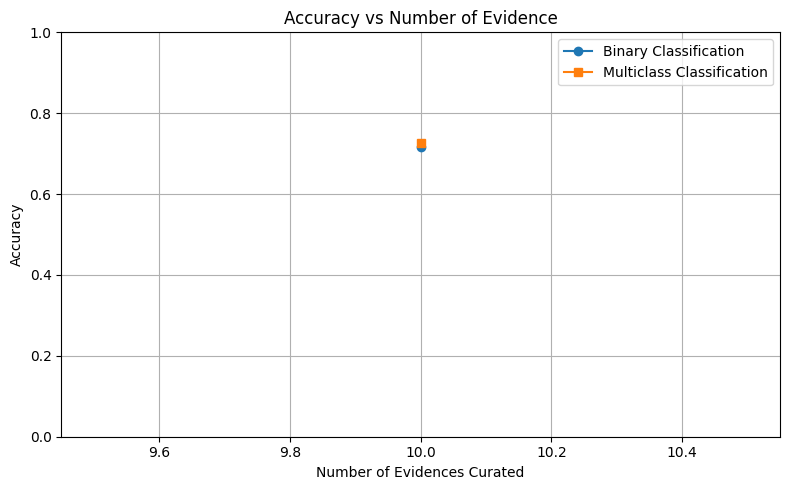

In [ ]:
# Plot accuracy vs number of evidence curated
accuracy_data = {model: {'binary': [], 'multiclass': []} for model in models}
evidence_counts = [10]
for model in models:
    for n_evidence_to_curate in evidence_counts:
        base_path = RESULTS_DIR / model / f"num_evidence_{n_evidence_to_curate}"
        for eval_strat, label in [('binary_classification', 'binary'), ('multiclass_classification', 'multiclass')]:
            with open(base_path / f"eval_stmt_chat_curation_{eval_strat}.json", "r") as f:
                res = json.load(f)
            preds = []
            for item in res:
                if item['llm_overall_prediction'] is not None:
                    preds.append(item['llm_overall_prediction'])
                else:
                    preds.append("incorrect")
            labels = [item['indra_curation'] for item in res]
            # Iterate through both lists and if at the same index, one is None, 
            acc = accuracy_score(labels, preds)
            accuracy_data[model][label].append(acc)
            print(f"{eval_strat} - Accuracy: {acc:.4f}")

# Plotting
n_evidence = len(evidence_counts)

# Compute average accuracy across models for each task
binary_accuracy = [x for x in accuracy_data[model]['binary']]
multiclass_accuracy = [x for x in accuracy_data[model]['multiclass']]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(evidence_counts, binary_accuracy, marker='o', label='Binary Classification')
plt.plot(evidence_counts, multiclass_accuracy, marker='s', label='Multiclass Classification')

plt.title("Accuracy vs Number of Evidence")
plt.xlabel("Number of Evidences Curated")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [13]:
# Evaluate the curated statements with different decision thresholds

models = ['gpt-4o-mini']
decision_thresholds = np.arange(0.0, 1.11, 0.1)

for model in models:

    with open(RESULTS_DIR / model / "num_evidence_10" / "chat_curation_binary_classification.json", "r") as f:
        chat_curation_binary_classification = json.load(f)

    with open(RESULTS_DIR / model / "num_evidence_10" / "chat_curation_multiclass_classification.json", "r") as f:
        chat_curation_multiclass_classification = json.load(f)

    for decision_threshold in decision_thresholds:
        for key, val in chat_curation_binary_classification['pa_hashes_dict'].items():
            if val['proportion_correct'] is None:
                val['overall_prediction'] = 'incorrect'
            elif val['proportion_correct'] >= decision_threshold:
                val['overall_prediction'] = 'correct'
            else:
                val['overall_prediction'] = 'incorrect'
        for key, val in chat_curation_multiclass_classification['pa_hashes_dict'].items():
            if val['proportion_correct'] is None:
                val['overall_prediction'] = 'incorrect'
            elif val['proportion_correct'] >= decision_threshold:
                val['overall_prediction'] = 'correct'
            else:
                val['overall_prediction'] = 'incorrect'

        threshold_str = f"{decision_threshold:.1f}".replace(".", "_")
        base_path = RESULTS_DIR / model / "decision_thresholds" / threshold_str
        if not base_path.exists():
            base_path.mkdir(parents=True)

        # Evaluate and save comparison
        eval_stmt_binary = curation_statement_comparison_json(chat_curation_binary_classification)
        with open(base_path / "eval_stmt_chat_curation_binary_classification.json", "w") as f:
            json.dump(eval_stmt_binary, f, indent=2)

        eval_stmt_multi = curation_statement_comparison_json(chat_curation_multiclass_classification)
        with open(base_path / "eval_stmt_chat_curation_multiclass_classification.json", "w") as f:
            json.dump(eval_stmt_multi, f, indent=2)


Processing LLM curations:   0%|          | 0/100 [00:00<?, ?it/s]INFO: [2025-09-04 10:51:26] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-32599288995876430
INFO: [2025-09-04 10:51:26] indra.sources.indra_db_rest.util - params: {'api_key': '[api-key]'}
INFO: [2025-09-04 10:51:26] indra.sources.indra_db_rest.util - data: None
Processing LLM curations:   1%|          | 1/100 [00:01<02:12,  1.33s/it]INFO: [2025-09-04 10:51:27] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-28715834116432266
INFO: [2025-09-04 10:51:27] indra.sources.indra_db_rest.util - params: {'api_key': '[api-key]'}
INFO: [2025-09-04 10:51:27] indra.sources.indra_db_rest.util - data: None
Processing LLM curations:   2%|▏         | 2/100 [00:01<01:22,  1.19it/s]INFO: [2025-09-04 10:51:28] indra.sources.indra_db_rest.util - query: https://db.indra.bio/curation/list/-28799404028067293
INFO: [2025-09-04 10:51:28] indra.sources.indra_db_rest.util - params: {'api_


Model: gpt-4o-mini, threshold: 0.0
binary_classification - Accuracy: 0.5455
multiclass_classification - Accuracy: 0.5455

Model: gpt-4o-mini, threshold: 0.1
binary_classification - Accuracy: 0.7475
multiclass_classification - Accuracy: 0.7475

Model: gpt-4o-mini, threshold: 0.2
binary_classification - Accuracy: 0.7374
multiclass_classification - Accuracy: 0.7475

Model: gpt-4o-mini, threshold: 0.3
binary_classification - Accuracy: 0.7374
multiclass_classification - Accuracy: 0.7374

Model: gpt-4o-mini, threshold: 0.4
binary_classification - Accuracy: 0.7374
multiclass_classification - Accuracy: 0.7374

Model: gpt-4o-mini, threshold: 0.5
binary_classification - Accuracy: 0.7172
multiclass_classification - Accuracy: 0.7273

Model: gpt-4o-mini, threshold: 0.6
binary_classification - Accuracy: 0.7071
multiclass_classification - Accuracy: 0.7071

Model: gpt-4o-mini, threshold: 0.7
binary_classification - Accuracy: 0.6970
multiclass_classification - Accuracy: 0.6970

Model: gpt-4o-mini, thr

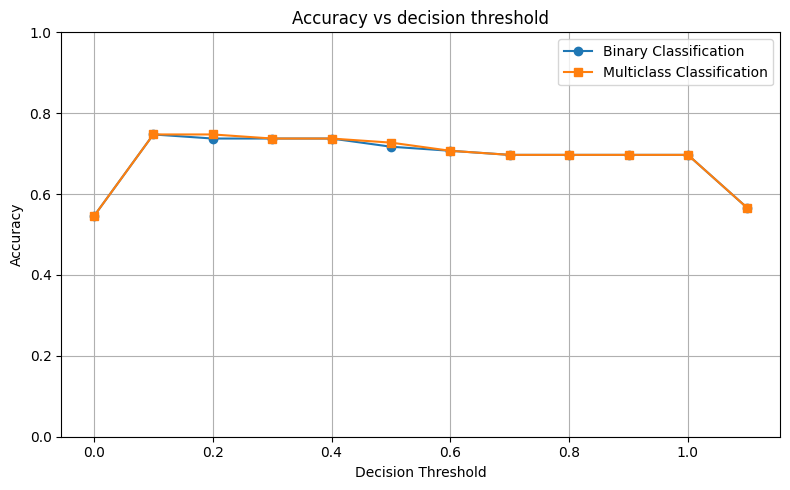

In [14]:
# Plot accuracy vs decision threshold
accuracy_data = {model: {'binary': [], 'multiclass': []} for model in models}
decision_thresholds = np.arange(0.0, 1.11, 0.1)
for model in models:
    for decision_threshold in decision_thresholds:
        threshold_str = f"{decision_threshold:.1f}".replace(".", "_")
        base_path = RESULTS_DIR / model / "decision_thresholds" / threshold_str
        print(f"\nModel: {model}, threshold: {decision_threshold:.1f}")
        for eval_strat, label in [('binary_classification', 'binary'), ('multiclass_classification', 'multiclass')]:
            with open(base_path / f"eval_stmt_chat_curation_{eval_strat}.json", "r") as f:
                res = json.load(f)
            preds = [item['llm_overall_prediction'] for item in res]
            labels = [item['indra_curation'] for item in res]
            acc = accuracy_score(labels, preds)
            accuracy_data[model][label].append(acc)
            print(f"{eval_strat} - Accuracy: {acc:.4f}")

# Plotting
n_evidence = len(evidence_counts)

# Compute average accuracy across models for each task
bin_accuracy = [x for x in accuracy_data[model]['binary']]
multi_accuracy = [x for x in accuracy_data[model]['multiclass']]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(decision_thresholds, bin_accuracy, marker='o', label='Binary Classification')
plt.plot(decision_thresholds, multi_accuracy, marker='s', label='Multiclass Classification')

plt.title("Accuracy vs decision threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
